In [1]:
!pip install -q opacus polars

In [2]:
import polars as pl

df = pl.read_csv("/content/wustl-ehms-2020_with_attacks_categories.csv", infer_schema_length=None).with_row_index()
# with_row_index() pra guardar explicitamente o índice e depois juntar os labels com join
print(df.shape)
print(df["Label"].value_counts().sort("Label"))
print(df["Attack Category"].value_counts().sort("count", descending=True))

(16318, 46)
shape: (2, 2)
┌───────┬───────┐
│ Label ┆ count │
│ ---   ┆ ---   │
│ i64   ┆ u32   │
╞═══════╪═══════╡
│ 0     ┆ 14272 │
│ 1     ┆ 2046  │
└───────┴───────┘
shape: (3, 2)
┌─────────────────┬───────┐
│ Attack Category ┆ count │
│ ---             ┆ ---   │
│ str             ┆ u32   │
╞═════════════════╪═══════╡
│ normal          ┆ 14272 │
│ Spoofing        ┆ 1124  │
│ Data Alteration ┆ 922   │
└─────────────────┴───────┘


## Significado das colunas

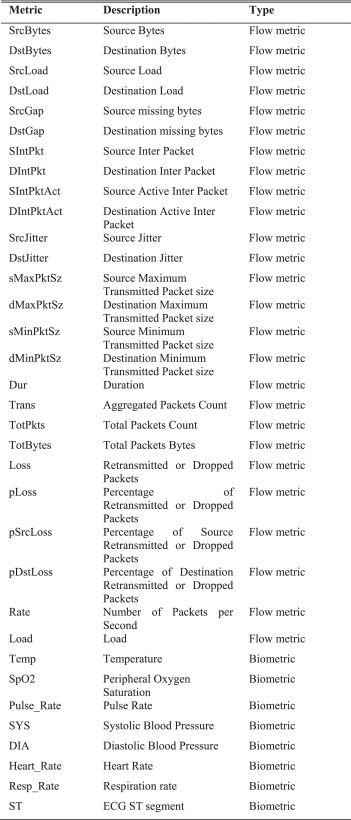

Fonte: Intrusion Detection System for Healthcare Systems Using Medical and Network Data: A Comparison Study - Hady et al. 2016 IEEE Systems and Information Engineering Design Symposium (SIEDS)

In [3]:
# O dataset tem mais dados do que é considerado features pelo artigo original do WUSTL, vou utilizar apenas essas
cols = ["index", "SrcBytes", "DstBytes", "SrcLoad", "DstLoad", "SrcGap", "DstGap", "SIntPkt", "DIntPkt", "SIntPktAct", "DIntPktAct", "SrcJitter", "DstJitter", "sMaxPktSz", "dMaxPktSz", "sMinPktSz", "dMinPktSz", "Dur", "Trans", "TotPkts", "TotBytes", "Loss", "pLoss", "pSrcLoss", "pDstLoss", "Rate", "Load", "Temp", "SpO2", "Pulse_Rate", "SYS", "DIA", "Heart_rate", "Resp_Rate", "ST", "Attack Category", "Label"]

[c for c in df.columns if c not in cols]

['Dir',
 'Flgs',
 'SrcAddr',
 'DstAddr',
 'Sport',
 'Dport',
 'SrcMac',
 'DstMac',
 'Packet_num']

In [4]:
df = df.drop([c for c in df.columns if c not in cols])

In [5]:
resumo = pl.DataFrame({
    "coluna": df.columns,
    "tipo": [str(t) for t in df.dtypes],
    "unicos": [df[c].n_unique() for c in df.columns],
}).sort("unicos")
with pl.Config(tbl_rows=50):
    print(resumo)

shape: (37, 3)
┌─────────────────┬─────────┬────────┐
│ coluna          ┆ tipo    ┆ unicos │
│ ---             ┆ ---     ┆ ---    │
│ str             ┆ str     ┆ i64    │
╞═════════════════╪═════════╪════════╡
│ SrcGap          ┆ Int64   ┆ 1      │
│ DstGap          ┆ Int64   ┆ 1      │
│ DIntPktAct      ┆ Int64   ┆ 1      │
│ dMinPktSz       ┆ Int64   ┆ 1      │
│ Trans           ┆ Int64   ┆ 1      │
│ sMaxPktSz       ┆ Int64   ┆ 2      │
│ dMaxPktSz       ┆ Int64   ┆ 2      │
│ sMinPktSz       ┆ Int64   ┆ 2      │
│ Label           ┆ Int64   ┆ 2      │
│ Loss            ┆ Int64   ┆ 3      │
│ pSrcLoss        ┆ Float64 ┆ 3      │
│ Attack Category ┆ String  ┆ 3      │
│ pDstLoss        ┆ Float64 ┆ 4      │
│ pLoss           ┆ Float64 ┆ 6      │
│ SIntPktAct      ┆ Float64 ┆ 8      │
│ TotPkts         ┆ Int64   ┆ 12     │
│ SYS             ┆ Int64   ┆ 12     │
│ DstBytes        ┆ Int64   ┆ 14     │
│ SrcBytes        ┆ Int64   ┆ 15     │
│ SpO2            ┆ Int64   ┆ 18     │
│ TotBytes

In [6]:
# colunas que não vão ajudar muito
colunas_constantes = [c for c in df.columns if df[c].n_unique() == 1]
print(colunas_constantes)
df = df.drop(colunas_constantes)

['SrcGap', 'DstGap', 'DIntPktAct', 'dMinPktSz', 'Trans']


In [7]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

y = df['Label'].to_numpy()
idx_tr, idx_te = train_test_split(range(len(df)), test_size=0.3, stratify=y, random_state=0)

def vazamento(c):
    col = df[c].cast(pl.Categorical).to_physical() if df[c].dtype == pl.Utf8 else df[c]
    x = col.to_numpy().reshape(-1, 1)
    puros = (
        df.group_by(c).agg(
            pl.col("Label").n_unique().alias("rotulos"), pl.len()
        ).filter(pl.col("rotulos") == 1)["len"].sum()
    )
    p = (HistGradientBoostingClassifier(random_state=0)
         .fit(x[idx_tr], y[idx_tr]).predict_proba(x[idx_te])[:, 1])
    return {"coluna": c, "unicos": df[c].n_unique(),
            "linhas_puras": round(puros / len(df), 3),
            "auroc_sozinha": round(roc_auc_score(y[idx_te], p), 3)}

cols = df.columns

META = ["index", "Attack Category", "Label"]
features = [c for c in df.columns if c not in META]
print(len(features))   # 29
tabela = pl.DataFrame([vazamento(c) for c in features]).sort("auroc_sozinha", descending=True)
with pl.Config(tbl_rows=50):
    print(tabela)

29
shape: (29, 4)
┌────────────┬────────┬──────────────┬───────────────┐
│ coluna     ┆ unicos ┆ linhas_puras ┆ auroc_sozinha │
│ ---        ┆ ---    ┆ ---          ┆ ---           │
│ str        ┆ i64    ┆ f64          ┆ f64           │
╞════════════╪════════╪══════════════╪═══════════════╡
│ DstJitter  ┆ 6046   ┆ 0.779        ┆ 0.849         │
│ DIntPkt    ┆ 6094   ┆ 0.774        ┆ 0.839         │
│ SrcLoad    ┆ 8353   ┆ 0.835        ┆ 0.812         │
│ SIntPkt    ┆ 8505   ┆ 0.835        ┆ 0.811         │
│ Dur        ┆ 8504   ┆ 0.835        ┆ 0.81          │
│ Load       ┆ 8385   ┆ 0.835        ┆ 0.808         │
│ Rate       ┆ 8425   ┆ 0.835        ┆ 0.808         │
│ DstLoad    ┆ 8195   ┆ 0.834        ┆ 0.807         │
│ SrcJitter  ┆ 16212  ┆ 0.999        ┆ 0.689         │
│ Temp       ┆ 53     ┆ 0.001        ┆ 0.601         │
│ Pulse_Rate ┆ 78     ┆ 0.012        ┆ 0.587         │
│ Resp_Rate  ┆ 50     ┆ 0.015        ┆ 0.558         │
│ SpO2       ┆ 18     ┆ 0.002        ┆ 0.553   

In [8]:
import numpy as np
from sklearn.model_selection import train_test_split

n = len(df)
cat = df["Attack Category"].to_numpy()

# Aleatório (IID): sorteia as linhas, 70/15/15, mantendo a proporção de cada categoria

tr, resto = train_test_split(np.arange(n), test_size=0.30, stratify=cat, random_state=42)
va, te = train_test_split(resto, test_size=0.50, stratify=cat[resto], random_state=42)
split_iid = np.empty(n, dtype=object)

split_iid[tr], split_iid[va], split_iid[te] = "train", "val", "test"

# Ordenado: 70/15/15 na ordem do arquivo, com 50 linhas descartadas entre os trechos para evitar vazamento de uma janela completa
GAP = 50
a, b = int(0.70 * n), int(0.85 * n)
split_ord = np.full(n, "gap", dtype=object)
split_ord[:a - GAP] = "train"
split_ord[a:b - GAP] = "val"
split_ord[b:] = "test"

df = df.with_columns(split_iid=pl.Series(split_iid), split_ord=pl.Series(split_ord))
for s in ("split_iid", "split_ord"):
    print(df.group_by(s).agg(linhas=pl.len(), ataque=pl.col("Label").mean().round(3),
                             primeira=pl.col("index").min(), ultima=pl.col("index").max())
            .sort("primeira"))


shape: (3, 5)
┌───────────┬────────┬────────┬──────────┬────────┐
│ split_iid ┆ linhas ┆ ataque ┆ primeira ┆ ultima │
│ ---       ┆ ---    ┆ ---    ┆ ---      ┆ ---    │
│ str       ┆ u32    ┆ f64    ┆ u32      ┆ u32    │
╞═══════════╪════════╪════════╪══════════╪════════╡
│ train     ┆ 11422  ┆ 0.125  ┆ 0        ┆ 16317  │
│ test      ┆ 2448   ┆ 0.125  ┆ 2        ┆ 16312  │
│ val       ┆ 2448   ┆ 0.125  ┆ 7        ┆ 16309  │
└───────────┴────────┴────────┴──────────┴────────┘
shape: (4, 5)
┌───────────┬────────┬────────┬──────────┬────────┐
│ split_ord ┆ linhas ┆ ataque ┆ primeira ┆ ultima │
│ ---       ┆ ---    ┆ ---    ┆ ---      ┆ ---    │
│ str       ┆ u32    ┆ f64    ┆ u32      ┆ u32    │
╞═══════════╪════════╪════════╪══════════╪════════╡
│ train     ┆ 11372  ┆ 0.128  ┆ 0        ┆ 11371  │
│ gap       ┆ 100    ┆ 0.0    ┆ 11372    ┆ 13869  │
│ val       ┆ 2398   ┆ 0.12   ┆ 11422    ┆ 13819  │
│ test      ┆ 2448   ┆ 0.124  ┆ 13870    ┆ 16317  │
└───────────┴────────┴────────┴─────

In [9]:
from sklearn.metrics import average_precision_score

X_all = df.select(features).to_numpy().astype(np.float32)
y_all = df["Label"].to_numpy().astype(np.float32)

def separa(split):
    s = df[split].to_numpy()
    tr = s == "train"
    media, desvio = X_all[tr].mean(axis=0), X_all[tr].std(axis=0)
    desvio[desvio == 0] = 1.0
    X = (X_all - media) / desvio
    return {p: (X[s == p], y_all[s == p]) for p in ("train", "val", "test")}

dados_iid, dados_ord = separa("split_iid"), separa("split_ord")

for nome, dados in [("IID", dados_iid), ("ordenado", dados_ord)]:
    m = HistGradientBoostingClassifier(random_state=0).fit(*dados["train"])
    for p in ("val", "test"):
        X, y = dados[p]
        prob = m.predict_proba(X)[:, 1]
        print(f"{nome:9s} {p:5s} {X.shape}  AUROC {roc_auc_score(y, prob):.3f}  AUPRC {average_precision_score(y, prob):.3f}")


IID       val   (2448, 29)  AUROC 0.953  AUPRC 0.858
IID       test  (2448, 29)  AUROC 0.952  AUPRC 0.850
ordenado  val   (2398, 29)  AUROC 0.774  AUPRC 0.410
ordenado  test  (2448, 29)  AUROC 0.859  AUPRC 0.715


In [10]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

DEV = torch.device("mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu"))
T = 24

def janelas(dados, T):
    # (n, 29) -> (n, 29, T): cada linha vira as T linhas anteriores do mesmo trecho, a atual na última posição
    out = {}
    for p, (X, y) in dados.items():
        linhas = np.arange(len(X))[:, None] - T + 1 + np.arange(T)
        out[p] = (X[np.maximum(linhas, 0)].transpose(0, 2, 1), y)
    return out

jan_iid = janelas(dados_iid, T=1)   # IID: só a linha atual
jan_ord = janelas(dados_ord, T=T)

class LCNN(nn.Module):
    def __init__(self, n_feat):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(n_feat, n_feat, 3, padding=1, groups=n_feat),
            nn.Conv1d(n_feat, 64, 1), nn.GELU(),
            nn.GroupNorm(1, 64), nn.Dropout(0.2),
            nn.Conv1d(64, 64, 3, padding=1, groups=64),
            nn.Conv1d(64, 128, 1), nn.GELU(),
            nn.AdaptiveAvgPool1d(1), nn.Flatten(),
            nn.Linear(128, 32), nn.GELU(), nn.Linear(32, 1),
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)

def loader(X, y, B, embaralha, seed=0):
    ds = TensorDataset(torch.from_numpy(X), torch.from_numpy(y))
    return DataLoader(ds, batch_size=B, shuffle=embaralha, generator=torch.Generator().manual_seed(seed))

@torch.no_grad()
def avalia(model, dl):
    model.eval()
    logits = torch.cat([model(xb.to(DEV)).cpu() for xb, _ in dl])
    y = torch.cat([yb for _, yb in dl]).numpy()
    p = torch.sigmoid(logits).numpy()
    return roc_auc_score(y, p), average_precision_score(y, p)

def treina_centralizado(jan, epocas=50, paciencia=10, seed=0):
    torch.manual_seed(seed)
    tr = loader(*jan["train"], 64, True, seed)
    va, te = loader(*jan["val"], 1024, False), loader(*jan["test"], 1024, False)
    model = LCNN(jan["train"][0].shape[1]).to(DEV)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    melhor, estado, sem_melhora = -1, None, 0
    for ep in range(epocas):
        model.train()
        for xb, yb in tr:
            xb, yb = xb.to(DEV), yb.to(DEV)
            opt.zero_grad()
            nn.functional.binary_cross_entropy_with_logits(model(xb), yb).backward()
            opt.step()
        auprc = avalia(model, va)[1]
        if auprc > melhor + 1e-3:
            melhor, sem_melhora = auprc, 0
            estado = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            sem_melhora += 1
            if sem_melhora >= paciencia:
                break
    model.load_state_dict(estado)
    return model, ep + 1, avalia(model, te)

for nome, jan in [("IID T=1", jan_iid), ("ordenado T=24", jan_ord)]:
    _, ep, (auroc, auprc) = treina_centralizado(jan)
    print(f"{nome:14s} {jan['train'][0].shape}  {ep:2d} épocas  test AUROC {auroc:.3f}  AUPRC {auprc:.3f}")


IID T=1        (11422, 29, 1)  50 épocas  test AUROC 0.868  AUPRC 0.707
ordenado T=24  (11372, 29, 24)  19 épocas  test AUROC 0.892  AUPRC 0.715


In [11]:
import copy, warnings
from opacus import PrivacyEngine
from opacus.accountants.utils import get_noise_multiplier

warnings.filterwarnings("ignore", message="Secure RNG turned off")
warnings.filterwarnings("ignore", message="Full backward hook")
if DEV.type != "cuda":
    torch.set_num_threads(1)

K, L = 10, 100
rng = np.random.default_rng(42)

# IID: rodízio dentro de cada categoria, então todo cliente fica com a mesma proporção de ataques
cat_tr = df.filter(pl.col("split_iid") == "train")["Attack Category"].to_numpy()
cli_iid = np.empty(len(cat_tr), dtype=int)
for c in np.unique(cat_tr):
    pos = rng.permutation(np.flatnonzero(cat_tr == c))
    cli_iid[pos] = np.arange(len(pos)) % K

# Ordenado: o treino é cortado em blocos de L linhas seguidas; os blocos são sorteados entre os clientes
bloco = np.arange(len(dados_ord["train"][1])) // L
rank = np.argsort(rng.permutation(bloco.max() + 1))
cli_ord = (rank % K)[bloco]

# A janela de treino do ordenado não pode atravessar o começo do bloco (seria olhar para outro cliente)
Xtr, ytr = dados_ord["train"]
linhas = np.arange(len(Xtr))[:, None] - T + 1 + np.arange(T)
jan_ord["train"] = (Xtr[np.maximum(linhas, (bloco * L)[:, None])].transpose(0, 2, 1), ytr)

for nome, cli, jan in [("IID", cli_iid, jan_iid), ("ordenado", cli_ord, jan_ord)]:
    y = jan["train"][1]
    print(f"{nome:9s} linhas {np.bincount(cli).tolist()}")
    print(f"{'':9s} ataque {[round(float(y[cli == k].mean()), 3) for k in range(K)]}")


IID       linhas [1143, 1143, 1143, 1143, 1143, 1142, 1142, 1141, 1141, 1141]
          ataque [0.126, 0.126, 0.126, 0.126, 0.126, 0.125, 0.125, 0.124, 0.124, 0.124]
ordenado  linhas [1200, 1200, 1200, 1200, 1100, 1100, 1100, 1072, 1100, 1100]
          ataque [0.138, 0.171, 0.129, 0.068, 0.106, 0.126, 0.149, 0.124, 0.16, 0.11]


In [12]:
def treina_local(modelo_global, dl, E, lr, engine=None, sigma=None, C=1.0):
    dev = DEV if (engine is None or DEV.type == "cuda") else torch.device("cpu")
    model = copy.deepcopy(modelo_global).to(dev)
    model.train()
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    if engine is not None:
        model, opt, dl = engine.make_private(module=model, optimizer=opt, data_loader=dl,
                                             noise_multiplier=sigma, max_grad_norm=C)
    perdas = []
    for _ in range(E):
        for xb, yb in dl:
            xb, yb = xb.to(dev), yb.to(dev)
            opt.zero_grad()
            perda = nn.functional.binary_cross_entropy_with_logits(model(xb), yb)
            perda.backward()
            opt.step()
            perdas.append(perda.item())
    estado = {k.removeprefix("_module."): v.detach().to(DEV) for k, v in model.state_dict().items()}
    return estado, float(np.mean(perdas))

def fedavg(modelo, estados, perdas, n):
    return {k: sum(nk / sum(n) * e[k] for nk, e in zip(n, estados)) for k in estados[0]}

def metade(X, y, qual):
    # divide a validação em blocos de 100 linhas alternados: 0 = treina a atenção, 1 = early stopping
    m = (np.arange(len(y)) // 100) % 2 == qual
    return X[m], y[m]

def federado(jan, cli, sigma=None, rodadas=80, E=2, B=64, lr=1e-3, paciencia=10, seed=0, delta=1e-5,
             agrega=fedavg):
    torch.manual_seed(seed)
    Xtr, ytr = jan["train"]
    dls = [loader(Xtr[cli == k], ytr[cli == k], B, True, seed) for k in range(K)]
    va, te = loader(*metade(*jan["val"], 1), 1024, False), loader(*jan["test"], 1024, False)
    n = [len(dl.dataset) for dl in dls]
    engines = [PrivacyEngine(accountant="rdp") if sigma else None for _ in dls]
    modelo = LCNN(Xtr.shape[1]).to(DEV)
    melhor, sem_melhora, eps = -1, 0, 0.0
    for t in range(rodadas):
        locais = [treina_local(modelo, dl, E, lr, eng, sigma) for dl, eng in zip(dls, engines)]
        estados, perdas = [e for e, _ in locais], [p for _, p in locais]
        modelo.load_state_dict(agrega(modelo, estados, perdas, n))
        if sigma:
            eps = max(eng.get_epsilon(delta) for eng in engines)
        auprc = avalia(modelo, va)[1]
        if auprc > melhor + 1e-3:
            melhor, sem_melhora = auprc, 0
            estado, r_melhor, eps_melhor = {k: v.clone() for k, v in modelo.state_dict().items()}, t + 1, eps
        else:
            sem_melhora += 1
            if sem_melhora >= paciencia:
                break
    modelo.load_state_dict(estado)
    return {"rodadas": t + 1, "melhor": r_melhor, "eps": eps_melhor, "test": avalia(modelo, te), "modelo": modelo}

def sigma_para(eps_alvo, n_min, B=64, E=2, rodadas=80, delta=1e-5):
    passos = int(np.ceil(n_min / B))
    return get_noise_multiplier(target_epsilon=eps_alvo, target_delta=delta, sample_rate=1 / passos,
                                steps=rodadas * E * passos, accountant="rdp")

for nome, cli, jan in [("IID", cli_iid, jan_iid), ("ordenado", cli_ord, jan_ord)]:
    r = federado(jan, cli)
    print(f"{nome:9s} FedAvg sem DP  {r['rodadas']:2d} rodadas (melhor {r['melhor']:2d})  "
          f"test AUROC {r['test'][0]:.3f}  AUPRC {r['test'][1]:.3f}")


IID       FedAvg sem DP  80 rodadas (melhor 79)  test AUROC 0.831  AUPRC 0.650
ordenado  FedAvg sem DP  69 rodadas (melhor 59)  test AUROC 0.911  AUPRC 0.769


In [13]:
configs = [("artigo, sigma=0.7", 0.7, 1e-3),
           ("eps<=5, lr do artigo", None, 1e-3),
           ("eps<=5, lr=1e-2", None, 1e-2)]

for nome, cli, jan in [("IID", cli_iid, jan_iid), ("ordenado", cli_ord, jan_ord)]:
    s5 = sigma_para(5.0, np.bincount(cli).min())
    for rotulo, sig, lr in configs:
        sig = sig or s5
        r = federado(jan, cli, sigma=sig, lr=lr)
        print(f"{nome:9s} {rotulo:22s} sigma {sig:.2f}  {r['rodadas']:2d} rodadas (melhor {r['melhor']:2d})  "
              f"eps {r['eps']:.1f}  test AUROC {r['test'][0]:.3f}  AUPRC {r['test'][1]:.3f}")


IID       artigo, sigma=0.7      sigma 0.70  80 rodadas (melhor 79)  eps 56.6  test AUROC 0.699  AUPRC 0.555
IID       eps<=5, lr do artigo   sigma 2.96  80 rodadas (melhor 77)  eps 4.9  test AUROC 0.758  AUPRC 0.492
IID       eps<=5, lr=1e-2        sigma 2.96  39 rodadas (melhor 29)  eps 2.8  test AUROC 0.751  AUPRC 0.546
ordenado  artigo, sigma=0.7      sigma 0.70  80 rodadas (melhor 80)  eps 58.9  test AUROC 0.681  AUPRC 0.431
ordenado  eps<=5, lr do artigo   sigma 3.04  80 rodadas (melhor 79)  eps 5.0  test AUROC 0.645  AUPRC 0.206
ordenado  eps<=5, lr=1e-2        sigma 3.04  64 rodadas (melhor 54)  eps 4.0  test AUROC 0.737  AUPRC 0.555


In [14]:
from torch.func import functional_call

class Atencao(nn.Module):
    # g_theta(h) = W2 tanh(W1 h + b1) + b2 (§3.3); pesos = softmax(beta * g) entre os clientes
    def __init__(self, beta=4.0, zera_saida=True):
        super().__init__()
        self.g = nn.Sequential(nn.Linear(4, 64), nn.Tanh(), nn.Linear(64, 1))
        if zera_saida:   # começa com g = 0 para todo cliente, ou seja, pesos iguais
            nn.init.zeros_(self.g[2].weight)
            nn.init.zeros_(self.g[2].bias)
        self.beta = beta

    def forward(self, h):
        return torch.softmax(self.beta * self.g(h).squeeze(-1), dim=0)

class AgregaAtencao:
    def __init__(self, jan, treinar=True, passos=5, lr=1e-2, W=3, seed=0):
        torch.manual_seed(seed)
        self.att = Atencao(zera_saida=treinar).to(DEV)
        self.opt = torch.optim.Adam(self.att.parameters(), lr=lr)
        self.treinar, self.passos, self.W = treinar, passos, W
        Xa, ya = metade(*jan["val"], 0)
        self.Xa, self.ya = torch.from_numpy(Xa).to(DEV), torch.from_numpy(ya).to(DEV)
        self.hist_perda, self.alphas = None, []

    def estado(self, modelo, estados, perdas, n):
        g = modelo.state_dict()
        delta = torch.stack([torch.cat([(e[k] - g[k]).flatten() for k in g]) for e in estados])
        media = delta.mean(dim=0)
        rho = ((delta - media).norm(dim=1) / media.norm()).cpu().tolist()
        if self.hist_perda is None:
            self.hist_perda = [[] for _ in estados]
        for h, p in zip(self.hist_perda, perdas):
            h.append(p)
        F = [float(np.mean(h[-self.W:])) for h in self.hist_perda]
        dF = [h[-1] - h[-2] if len(h) > 1 else 0.0 for h in self.hist_perda]
        return torch.tensor([[np.log(nk), f, d, r] for nk, f, d, r in zip(n, F, dF, rho)],
                            dtype=torch.float32, device=DEV)

    def __call__(self, modelo, estados, perdas, n):
        h = self.estado(modelo, estados, perdas, n)
        mistura = lambda a: {k: sum(ak * e[k] for ak, e in zip(a, estados)) for k in estados[0]}
        if self.treinar:
            modelo.eval()
            for _ in range(self.passos):
                logits = functional_call(modelo, mistura(self.att(h)), (self.Xa,))
                perda = nn.functional.binary_cross_entropy_with_logits(logits, self.ya)
                self.opt.zero_grad()
                perda.backward()
                self.opt.step()
        with torch.no_grad():
            alpha = self.att(h)
        self.alphas.append(alpha.cpu().numpy())
        return mistura(alpha)


In [15]:
# Dirichlet(0,5) sobre os blocos, pela categoria de ataque mais comum em cada bloco
cat_ord = df.filter(pl.col("split_ord") == "train")["Attack Category"].to_numpy()

def cat_do_bloco(b):
    c = cat_ord[bloco == b]
    s, d = (c == "Spoofing").sum(), (c == "Data Alteration").sum()
    return "normal" if s + d == 0 else ("Spoofing" if s >= d else "Data Alteration")

cat_bloco = np.array([cat_do_bloco(b) for b in range(bloco.max() + 1)])
tam_bloco = np.bincount(bloco)

def dirichlet(cat, peso, alpha=0.5, minimo=64):
    for _ in range(1000):
        cli = np.empty(len(cat), dtype=int)
        for c in np.unique(cat):
            pos = rng.permutation(np.flatnonzero(cat == c))
            cortes = (np.cumsum(rng.dirichlet(np.full(K, alpha)))[:-1] * len(pos)).astype(int)
            for k, parte in enumerate(np.split(pos, cortes)):
                cli[parte] = k
        if np.bincount(cli, weights=peso, minlength=K).min() >= minimo:
            return cli
    raise RuntimeError("nenhuma partição com o mínimo")

cli_ord_nao_iid = dirichlet(cat_bloco, tam_bloco)[bloco]
y = jan_ord["train"][1]
print("linhas", np.bincount(cli_ord_nao_iid).tolist())
print("ataque", [round(float(y[cli_ord_nao_iid == k].mean()), 3) for k in range(K)])


linhas [700, 1200, 372, 500, 300, 800, 700, 800, 2600, 3400]
ataque [0.189, 0.209, 0.212, 0.112, 0.137, 0.0, 0.0, 0.046, 0.13, 0.153]


In [16]:
cenarios = [("IID", cli_iid, jan_iid), ("ordenado", cli_ord, jan_ord),
            ("ordenado não-IID", cli_ord_nao_iid, jan_ord)]
for nome, cli, jan in cenarios:
    for rotulo, agrega in [("FedAvg", fedavg), ("atenção fixa", AgregaAtencao(jan, treinar=False)),
                           ("atenção treinada", AgregaAtencao(jan))]:
        r = federado(jan, cli, agrega=agrega)
        pesos = "" if agrega is fedavg else f"  pesos {[round(float(a), 2) for a in agrega.alphas[r['melhor'] - 1]]}"
        print(f"{nome:17s} {rotulo:17s} {r['rodadas']:2d} rodadas (melhor {r['melhor']:2d})  "
              f"test {r['test'][0]:.3f}/{r['test'][1]:.3f}{pesos}")


IID               FedAvg            80 rodadas (melhor 79)  test 0.831/0.650
IID               atenção fixa      80 rodadas (melhor 79)  test 0.831/0.650  pesos [0.12, 0.1, 0.09, 0.1, 0.1, 0.09, 0.09, 0.12, 0.1, 0.1]
IID               atenção treinada  80 rodadas (melhor 79)  test 0.830/0.650  pesos [0.03, 0.13, 0.16, 0.08, 0.12, 0.12, 0.12, 0.04, 0.11, 0.1]
ordenado          FedAvg            69 rodadas (melhor 59)  test 0.911/0.769
ordenado          atenção fixa      69 rodadas (melhor 59)  test 0.914/0.774  pesos [0.1, 0.09, 0.1, 0.1, 0.1, 0.11, 0.09, 0.11, 0.11, 0.1]
ordenado          atenção treinada  29 rodadas (melhor 19)  test 0.860/0.648  pesos [0.04, 0.03, 0.01, 0.01, 0.02, 0.23, 0.03, 0.06, 0.57, 0.0]
ordenado não-IID  FedAvg            41 rodadas (melhor 31)  test 0.899/0.757
ordenado não-IID  atenção fixa      53 rodadas (melhor 43)  test 0.921/0.787  pesos [0.11, 0.1, 0.08, 0.07, 0.06, 0.1, 0.1, 0.1, 0.13, 0.15]
ordenado não-IID  atenção treinada  49 rodadas (melhor 39)  

In [17]:
# Cada execução roda em um processo Python novo (avaliacao.py, que repete o preparo deste notebook).
# Vários processos ao mesmo tempo dividem a GPU; o gargalo é o Python de cada um, então o limite é o número de núcleos.
# Suba o avaliacao.py para /content antes. Pode rodar de novo à vontade: o que já tem arquivo em OUT é pulado.
import json, os, subprocess
from concurrent.futures import ThreadPoolExecutor, as_completed

OUT = "/content/avaliacao"
CSV = "/content/wustl-ehms-2020_with_attacks_categories.csv"
CONFIGS = ["gb", "central", "fedavg", "atencao", "fedavg_dp", "atencao_dp", "artigo"]
os.makedirs(OUT, exist_ok=True)

feito = lambda sp, cfg, s: os.path.exists(f"{OUT}/{sp}_{cfg}_{s}.npz")
# as mais demoradas (com DP) entram primeiro, para não sobrarem sozinhas no fim
jobs = [(sp, cfg, s) for cfg in reversed(CONFIGS) for s in range(5) for sp in ("ord", "iid")
        if not feito(sp, cfg, s)]

def lanca(job):
    r = subprocess.run(["python", "avaliacao.py", *map(str, job), "--csv", CSV, "--out", OUT],
                       capture_output=True, text=True)
    return job, r.returncode, r.stdout.strip(), r.stderr.strip().splitlines()[-1:]

PARALELO = os.cpu_count()
print(f"{len(jobs)} execuções, {PARALELO} por vez")
with ThreadPoolExecutor(PARALELO) as ex:
    for f in as_completed([ex.submit(lanca, j) for j in jobs]):
        job, codigo, saida, erro = f.result()
        print(saida if codigo == 0 else f"ERRO {job}: {erro}", flush=True)


70 execuções, 12 por vez
iid artigo 1 {'rodadas': 25, 'melhor': 15, 'eps': 21.174328717130305, 'sigma': 0.7} 0.754
iid artigo 4 {'rodadas': 25, 'melhor': 15, 'eps': 21.174328717130305, 'sigma': 0.7} 0.756
iid artigo 3 {'rodadas': 29, 'melhor': 19, 'eps': 24.019166460755734, 'sigma': 0.7} 0.752
iid atencao_dp 0 {'rodadas': 36, 'melhor': 26, 'eps': 2.6700392364905268, 'sigma': 2.958984375} 0.743
iid atencao_dp 1 {'rodadas': 15, 'melhor': 5, 'eps': 1.11227399333548, 'sigma': 2.958984375} 0.762
ord atencao_dp 0 {'rodadas': 49, 'melhor': 39, 'eps': 3.3398545543697824, 'sigma': 3.037109375} 0.836
ord atencao_dp 1 {'rodadas': 27, 'melhor': 17, 'eps': 2.1230627734424696, 'sigma': 3.037109375} 0.71
ord artigo 2 {'rodadas': 62, 'melhor': 52, 'eps': 44.60072824808409, 'sigma': 0.7} 0.681
iid atencao_dp 2 {'rodadas': 35, 'melhor': 25, 'eps': 2.613569761840909, 'sigma': 2.958984375} 0.748
iid atencao_dp 3 {'rodadas': 29, 'melhor': 19, 'eps': 2.252009547529722, 'sigma': 2.958984375} 0.751
ord artigo

In [20]:
import glob
from scipy import stats

FPR_ALVO = 0.01

def arquivos(split, cfg):
    # pelo número da seed: um glob "fedavg_*" pegaria também os "fedavg_dp_*"
    return [f for f in (f"{OUT}/{split}_{cfg}_{s}.npz" for s in range(5)) if os.path.exists(f)]

def partes(split):
    s = df[split].to_numpy()
    cat = df["Attack Category"].to_numpy()
    return {p: cat[s == p] for p in ("val", "test")}

def metricas(pv, pt, cat_v, cat_t, episodios):
    y = (cat_t != "normal").astype(int)
    m = {"AUROC": roc_auc_score(y, pt), "AUPRC": average_precision_score(y, pt)}
    for tipo in ("Spoofing", "Data Alteration"):
        sel = (cat_t == tipo) | (cat_t == "normal")
        m[f"AUROC {tipo}"] = roc_auc_score(y[sel], pt[sel])
    if episodios:
        # limiar: só 1% das linhas normais da validação passam dele
        lim = np.quantile(pv[cat_v == "normal"], 1 - FPR_ALVO)
        alarme = pt >= lim
        seg = np.r_[0, np.cumsum(cat_t[1:] != cat_t[:-1])]
        detect, atraso = [], []
        for e in np.unique(seg[y == 1]):
            a = alarme[seg == e]
            detect.append(a.any())
            if a.any():
                atraso.append(int(np.argmax(a)))
        m["episódios detectados"] = int(np.sum(detect))
        m["atraso médio (linhas)"] = float(np.mean(atraso)) if atraso else np.nan
        m["falso positivo no teste"] = float(alarme[y == 0].mean())
    return m

def ic95(x):
    x = np.asarray(x, dtype=float)
    return x.mean(), stats.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))

linhas = []
for split, col in (("ord", "split_ord"), ("iid", "split_iid")):
    cat = partes(col)
    for cfg in CONFIGS:
        if not arquivos(split, cfg):
            continue
        runs = []
        for f in arquivos(split, cfg):
            p = np.load(f)
            m = metricas(p["val"], p["test"], cat["val"], cat["test"], episodios=(split == "ord"))
            m.update(json.load(open(f.replace(".npz", ".json"))))
            runs.append(m)
        linha = {"split": split, "config": cfg, "seeds": len(runs)}
        for chave in runs[0]:
            v = [r[chave] for r in runs if r.get(chave) is not None]
            if len(v) == len(runs) and len(v) > 1:
                media, meia = ic95(v)
                linha[chave] = f"{media:.3f} ± {meia:.3f}"
        linhas.append(linha)

with pl.Config(tbl_rows=30, tbl_cols=20, fmt_str_lengths=20, tbl_width_chars=250):
    print(pl.DataFrame(linhas))

shape: (14, 15)
┌───────┬────────────┬───────┬───────────────┬───────────────┬────────────────┬───────────────┬────────────────┬─────────────────────────┬────────────────────────┬────────────────┬─────────────────┬─────────────────┬─────────────────┬───────────────┐
│ split ┆ config     ┆ seeds ┆ AUROC         ┆ AUPRC         ┆ AUROC Spoofing ┆ AUROC Data    ┆ episódios      ┆ atraso médio (linhas…   ┆ falso positivo no te…  ┆ epocas         ┆ rodadas         ┆ melhor          ┆ eps             ┆ sigma         │
│ ---   ┆ ---        ┆ ---   ┆ ---           ┆ ---           ┆ ---            ┆ Alteratio…    ┆ detectados     ┆ ---                     ┆ ---                    ┆ ---            ┆ ---             ┆ ---             ┆ ---             ┆ ---           │
│ str   ┆ str        ┆ i64   ┆ str           ┆ str           ┆ str            ┆ ---           ┆ ---            ┆ str                     ┆ str                    ┆ str            ┆ str             ┆ str             ┆ str           

In [21]:
cat_t = partes("split_ord")["test"]
y_t = (cat_t != "normal").astype(int)
seg = np.r_[0, np.cumsum(cat_t[1:] != cat_t[:-1])]
trechos = [np.flatnonzero(seg == s) for s in np.unique(seg)]
print(f"teste ordenado: {len(trechos)} trechos, {int(sum(y_t[t[0]] for t in trechos))} episódios de ataque")

def bootstrap(cfg, n=2000, seed=0):
    ps = [np.load(f)["test"] for f in arquivos("ord", cfg)]
    r = np.random.default_rng(seed)
    vals = []
    for _ in range(n):
        idx = np.concatenate([trechos[i] for i in r.integers(0, len(trechos), len(trechos))])
        if y_t[idx].min() == y_t[idx].max():
            continue
        vals.append(np.mean([roc_auc_score(y_t[idx], p[idx]) for p in ps]))
    return np.mean([roc_auc_score(y_t, p) for p in ps]), np.percentile(vals, [2.5, 97.5])

for cfg in CONFIGS:
    if arquivos("ord", cfg):
        media, (lo, hi) = bootstrap(cfg)
        print(f"{cfg:11s} AUROC {media:.3f}  IC 95% por episódio [{lo:.3f}, {hi:.3f}]")

teste ordenado: 25 trechos, 12 episódios de ataque
gb          AUROC 0.859  IC 95% por episódio [0.735, 0.965]
central     AUROC 0.896  IC 95% por episódio [0.802, 0.970]
fedavg      AUROC 0.870  IC 95% por episódio [0.773, 0.961]
atencao     AUROC 0.842  IC 95% por episódio [0.713, 0.950]
fedavg_dp   AUROC 0.729  IC 95% por episódio [0.543, 0.897]
atencao_dp  AUROC 0.769  IC 95% por episódio [0.637, 0.890]
artigo      AUROC 0.704  IC 95% por episódio [0.529, 0.855]
